# 05 · Recurrent Networks and Time-Series Forecasting

Images have a spatial structure; many other signals have a **temporal** one: electricity demand, sensor readings, prices, speech, text. The order matters, the length varies, and what happens now depends on what happened before.

A **recurrent neural network** reads a sequence one step at a time and carries a memory forward. In this notebook you will:

| Section | Idea | Experiment |
|---|---|---|
| 1-3 | the recurrent loop, LSTM gates | write an RNN cell by hand |
| 4-5 | forecasting with calendar features | an RNN and an LSTM forecast 20 unseen days of hourly demand, against a seasonal-naive baseline |
| 6 | how far back can a network remember? | measure how quickly gradients vanish through time, and what the LSTM forget gate changes |
| 7 | direct multi-horizon forecasting | predict the next 24 hours in one shot instead of feeding predictions back |

Everything runs on a CPU in a few minutes with a synthetic dataset generated in the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. The idea: a loop with memory

An RNN reads a sequence one step at a time and keeps a **hidden state** $h_t$, a summary of everything seen so far:

$$ h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h), \qquad \hat y_t = W_{hy} h_t + b_y $$

The **same weights** are used at every step (like a CNN shares weights across space, an RNN shares them across time). Unrolled in time it is just a very deep network:

```
        y1          y2          y3                yT
        ▲           ▲           ▲                 ▲
h0 ──► [cell] ──h1─► [cell] ──h2─► [cell] ──h3─ ... ─► [cell] ──► hT
        ▲           ▲           ▲                 ▲
        x1          x2          x3                xT
```

Training uses **backpropagation through time (BPTT)**: ordinary backprop on the unrolled graph. Because the gradient is multiplied by $W_{hh}$ and $\tanh'$ at every step, it **vanishes** (or explodes) over long sequences, so a vanilla RNN forgets what happened more than a few dozen steps ago.

## 2. The LSTM fix: gated memory

The **Long Short-Term Memory** cell (Hochreiter & Schmidhuber, 1997) adds a separate **cell state** $c_t$ that flows through time mostly by *addition*, controlled by three sigmoid **gates**:

| Gate | Formula | Meaning |
|---|---|---|
| forget $f_t$ | $\sigma(W_f[h_{t-1},x_t]+b_f)$ | what to erase from memory |
| input $i_t$ | $\sigma(W_i[h_{t-1},x_t]+b_i)$ | how much new information to write |
| candidate $\tilde c_t$ | $\tanh(W_c[h_{t-1},x_t]+b_c)$ | the new information |
| output $o_t$ | $\sigma(W_o[h_{t-1},x_t]+b_o)$ | what to expose as $h_t$ |

$$ c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t) $$

When $f_t \approx 1$ the gradient flows along $c_t$ almost untouched: the same "additive highway" idea as ResNet's residual connections and the transformer's residual stream. The **GRU** is a lighter variant with two gates.

## 3. An RNN cell written by hand

In [2]:
class ManualRNN(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.Wxh = nn.Linear(n_in, n_hidden)
        self.Whh = nn.Linear(n_hidden, n_hidden, bias=False)
        self.n_hidden = n_hidden
    def forward(self, x):                       # x: (batch, time, features)
        h = torch.zeros(x.shape[0], self.n_hidden)
        states = []
        for t in range(x.shape[1]):             # the recurrence: same weights at every step
            h = torch.tanh(self.Wxh(x[:, t]) + self.Whh(h))
            states.append(h)
        return torch.stack(states, dim=1)

rnn = ManualRNN(1, 4)
print("hidden states shape:", tuple(rnn(torch.randn(2, 10, 1)).shape), "= (batch, time, hidden)")

hidden states shape: (2, 10, 4) = (batch, time, hidden)


## 4. Data: a synthetic hourly "demand" signal

Many real series (electricity load, web traffic, sales) look like this: a **daily** cycle, a **weekly** cycle (weekends lower), a slow **trend** and **noise**. We generate 120 days of hourly data, train on the first 100 days and forecast the rest.

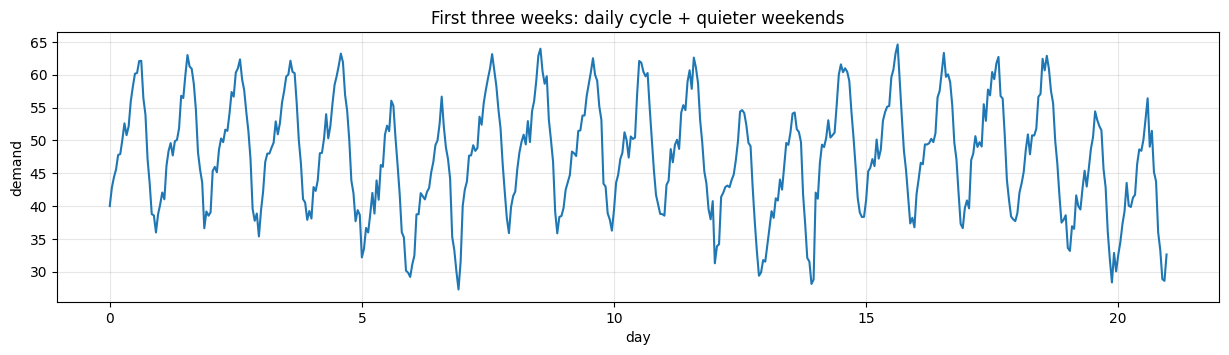

In [3]:
rng = np.random.default_rng(7)
hours = np.arange(24 * 120)
daily = 10 * np.sin(2 * np.pi * (hours % 24 - 6) / 24) + 4 * np.sin(4 * np.pi * (hours % 24) / 24)
weekend = np.where((hours // 24) % 7 >= 5, -8.0, 0.0)
trend = 0.01 * hours / 24
noise_sd = 1.5
series = 50 + daily + weekend + trend + rng.normal(0, noise_sd, len(hours))

split = 24 * 100
mu, sd = series[:split].mean(), series[:split].std()
s_norm = (series - mu) / sd                       # always normalise inputs for neural nets

plt.figure(figsize=(15, 3.5))
plt.plot(hours[:24 * 21] / 24, series[:24 * 21])
plt.xlabel("day"); plt.ylabel("demand"); plt.title("First three weeks: daily cycle + quieter weekends"); plt.grid(alpha=0.3); plt.show()

We turn the series into supervised examples with a **sliding window**: the model sees the last `W = 48` hours and predicts the next hour.

Each time step carries 5 features: the (normalised) demand plus four **calendar features**, $\sin/\cos$ of the hour-of-day and hour-of-week. Calendar features are known in advance, so they are also available when forecasting the future, and they tell the network *where in the week it is* without having to remember a full week of history. This is standard practice in real demand forecasting.

In [4]:
W = 48
calendar = np.stack([np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24),
                     np.sin(2 * np.pi * hours / 168), np.cos(2 * np.pi * hours / 168)], axis=1)

def make_input(values, t):
    # values: the W demand values before hour t; calendar shifted by one so each step also "knows" the next hour
    return np.concatenate([np.asarray(values)[:, None], calendar[t - W + 1:t + 1]], axis=1)

def windows(s, start, end):
    X = [make_input(s[t - W:t], t) for t in range(start + W, end)]
    Y = [s[t] for t in range(start + W, end)]
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(Y), dtype=torch.float32)

Xs_tr, ys_tr = windows(s_norm, 0, split)
print("training windows:", tuple(Xs_tr.shape), "= (samples, time steps, features) -> targets", tuple(ys_tr.shape))

class Forecaster(nn.Module):
    def __init__(self, kind="lstm", hidden=32):
        super().__init__()
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = cls(input_size=5, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)    # use the last hidden state

def fit_forecaster(model, epochs=10, lr=3e-3, batch=64):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xs_tr))
        for i in range(0, len(Xs_tr), batch):
            b = perm[i:i + batch]
            loss = F.mse_loss(model(Xs_tr[b]), ys_tr[b])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)      # standard protection against exploding gradients
            opt.step(); losses.append(loss.item())
    return losses

models = {}
for kind in ["rnn", "lstm"]:
    torch.manual_seed(0)
    t0 = time.time()
    models[kind] = Forecaster(kind)
    l = fit_forecaster(models[kind])
    print(f"{kind.upper():4s} params {count_params(models[kind]):5d}  final train MSE {np.mean(l[-50:]):.4f}  ({time.time() - t0:.0f}s)")

training windows: (2352, 48, 5) = (samples, time steps, features) -> targets (2352,)


RNN  params  1281  final train MSE 0.0454  (7s)


LSTM params  5025  final train MSE 0.0394  (4s)


## 5. Forecasting the unseen 20 days

Two ways to use the model:
* **One-step-ahead:** at each hour, feed the *true* previous 48 hours and predict the next one.
* **Recursive multi-step:** predict hour 1, append the prediction to the input, predict hour 2, and so on for a whole week. Errors compound, so this is much harder and closer to real forecasting.

We compare against the **seasonal naive** baseline ("same hour last week"), a surprisingly strong benchmark every forecaster must beat. The noise we added has a standard deviation of 1.5, so an RMSE of 1.5 is the best any model could possibly achieve.

model     1-step RMSE   recursive 7-day RMSE
(floor)          1.50                   1.50
naive            2.12                   2.15


RNN              1.89                   2.44
LSTM             1.80                   2.07


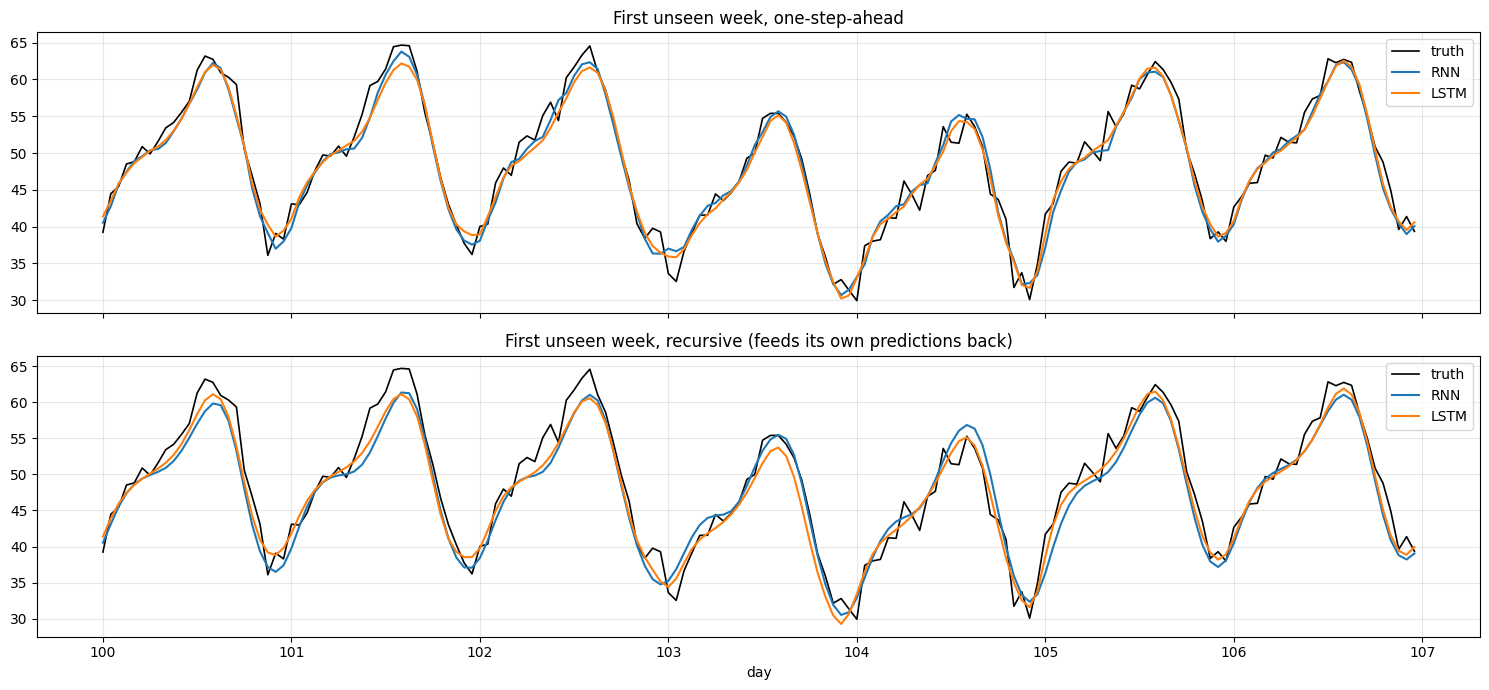

In [5]:
def one_step(model):
    Xv, _ = windows(s_norm, split - W, len(s_norm))     # one window per unseen hour
    with torch.no_grad():
        return model(Xv).numpy() * sd + mu

def recursive(model, horizon):
    hist = list(s_norm[split - W:split])
    preds = []
    with torch.no_grad():
        for k in range(horizon):
            x = torch.tensor(make_input(hist[-W:], split + k), dtype=torch.float32).unsqueeze(0)
            p = model(x).item()
            preds.append(p); hist.append(p)               # the prediction becomes the next input
    return np.array(preds) * sd + mu

truth = series[split:]
naive = series[split - 168:len(series) - 168]
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

print(f"{'model':8s} {'1-step RMSE':>12s} {'recursive 7-day RMSE':>22s}")
print(f"{'(floor)':8s} {noise_sd:12.2f} {noise_sd:22.2f}")
print(f"{'naive':8s} {rmse(naive, truth):12.2f} {rmse(naive[:168], truth[:168]):22.2f}")
forecasts = {}
for kind, m in models.items():
    os_pred = one_step(m)
    rec = recursive(m, 168)
    forecasts[kind] = (os_pred, rec)
    print(f"{kind.upper():8s} {rmse(os_pred, truth):12.2f} {rmse(rec, truth[:168]):22.2f}")

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
t = hours[split:split + 168] / 24
for ax, (label, idx) in zip(axes, [("one-step-ahead", 0), ("recursive (feeds its own predictions back)", 1)]):
    ax.plot(t, truth[:168], color="k", lw=1.2, label="truth")
    for kind in models:
        ax.plot(t, forecasts[kind][idx][:168], lw=1.5, label=kind.upper())
    ax.set_title(f"First unseen week, {label}"); ax.legend(loc="upper right"); ax.grid(alpha=0.3)
axes[1].set_xlabel("day"); plt.tight_layout(); plt.show()

Things to notice:
* Both networks learn the daily and weekly shapes from data and beat the seasonal naive baseline one step ahead.
* The LSTM is usually the more stable of the two in recursive mode: its gated cell state carries information across many steps, which is exactly where vanilla RNN gradients vanish.
* Recursive forecasts degrade as errors compound. Section 7 removes that feedback loop.

## 6. How far back can a recurrent network remember?

Section 1 claimed that gradients vanish through time. We can measure it directly. Feed a 100-step random sequence into a network and compute how much the **final** hidden state depends on each input:

$$ \text{sensitivity}(t) = \left\| \frac{\partial h_T}{\partial x_t} \right\| $$

If it decays quickly as $t$ moves away from $T$, the network cannot learn long-range dependencies: the training signal from the loss never reaches those early steps.

We compare a vanilla RNN with LSTMs that differ **only in the initial bias of the forget gate**. With bias 0 the forget gate starts at $\sigma(0) = 0.5$, so the cell state is halved at every step, much like the RNN's repeated multiplication. A positive bias starts the gate close to 1 ("remember by default"), a trick recommended by Gers et al. (2000) and Jozefowicz et al. (2015). The GRU's equivalent is its *update* gate.

RNN                                      sensitivity 50 steps back: 7.6e-12
LSTM, forget bias 0 (PyTorch default)    sensitivity 50 steps back: 8.2e-12
LSTM, forget bias 1                      sensitivity 50 steps back: 2.0e-05
LSTM, forget bias 3                      sensitivity 50 steps back: 2.0e-02


GRU, update bias 3                       sensitivity 50 steps back: 2.9e-03


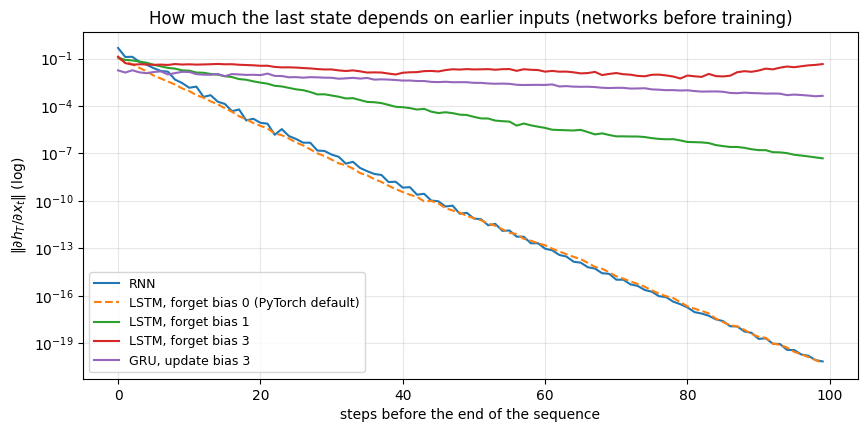

In [6]:
def gated(cls, gate_bias):
    net = cls(input_size=1, hidden_size=32, batch_first=True)
    with torch.no_grad():
        # PyTorch stacks the gate parameters; rows 32:64 are the LSTM forget gate and the GRU update gate
        net.bias_ih_l0[32:64].fill_(gate_bias / 2); net.bias_hh_l0[32:64].fill_(gate_bias / 2)
    return net

variants = {
    "RNN": lambda: nn.RNN(input_size=1, hidden_size=32, batch_first=True),
    "LSTM, forget bias 0 (PyTorch default)": lambda: gated(nn.LSTM, 0.0),
    "LSTM, forget bias 1": lambda: gated(nn.LSTM, 1.0),
    "LSTM, forget bias 3": lambda: gated(nn.LSTM, 3.0),
    "GRU, update bias 3": lambda: gated(nn.GRU, 3.0),
}
T = 100
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, make in variants.items():
    sens = []
    for seed in range(5):
        torch.manual_seed(seed)
        net = make()
        x = torch.randn(1, T, 1, requires_grad=True)
        out, _ = net(x)
        out[0, -1].sum().backward()
        sens.append(x.grad[0, :, 0].abs().numpy())
    s = np.mean(sens, 0)[::-1]
    ax.semilogy(np.arange(T), s, label=name, ls="--" if "default" in name else "-")
    print(f"{name:40s} sensitivity 50 steps back: {s[50]:.1e}")
ax.set_xlabel("steps before the end of the sequence"); ax.set_ylabel(r"$\|\partial h_T / \partial x_t\|$ (log)")
ax.set_title("How much the last state depends on earlier inputs (networks before training)"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

Two lessons in one plot:

* With default settings the LSTM forgets **as fast as the vanilla RNN**: the dependence on an input 50 steps back is smaller than $10^{-10}$ for both. The gates make long memory *possible*, they do not make it automatic.
* Opening the forget gate changes everything. With bias 3 the cell state is carried almost unchanged, and the sensitivity barely decays over 100 steps. During training an LSTM can learn such gate values where the task needs them, and starting from a positive forget bias makes that much easier.

A vanilla RNN has no such knob: its memory is multiplied by $W_{hh}$ and squashed by $\tanh$ at every step, and keeping that product close to 1 for long stretches is exactly what gradient descent struggles to do. This is the practical reason LSTMs and GRUs replaced plain RNNs, and the same "additive path for the gradient" idea reappears in ResNets (notebook 04) and transformers (notebook 07).

## 7. Direct multi-horizon forecasting

Real forecasts are usually needed for a whole horizon at once, for example **tomorrow's 24 hours**, issued every day at midnight (this is how day-ahead electricity markets work). Two ways to get there:

* **Recursive:** the one-step model from section 5, run 24 times, feeding each prediction back as input.
* **Direct:** a model whose output layer has 24 units, trained to predict all 24 hours from the same 48-hour history. No feedback loop, so no compounding errors, and each output can specialise in its own horizon.

We evaluate both the honest way: one forecast per unseen day, issued at midnight, scored over the next 24 hours.

direct model trained in 4s



day-ahead RMSE over 20 unseen days (noise floor 1.5)
  seasonal naive   2.12
  LSTM recursive   2.12
  LSTM direct      1.70


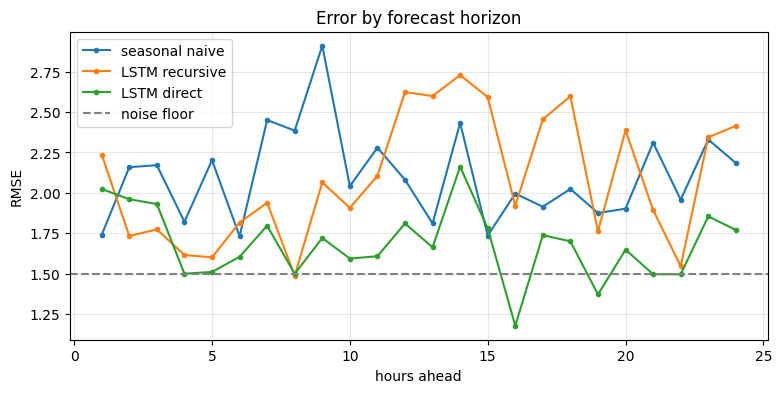

In [7]:
H = 24
def windows_direct(s, start, end, step=1):
    X, Y = [], []
    for t in range(start + W, end - H + 1, step):
        X.append(make_input(s[t - W:t], t)); Y.append(s[t:t + H])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(Y), dtype=torch.float32)

class DirectForecaster(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.LSTM(input_size=5, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, H)             # one output per future hour
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])

Xd_tr, Yd_tr = windows_direct(s_norm, 0, split)
torch.manual_seed(0)
direct = DirectForecaster()
opt = torch.optim.Adam(direct.parameters(), lr=3e-3)
t0 = time.time()
for ep in range(10):
    perm = torch.randperm(len(Xd_tr))
    for i in range(0, len(Xd_tr), 64):
        b = perm[i:i + 64]
        loss = F.mse_loss(direct(Xd_tr[b]), Yd_tr[b])
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(direct.parameters(), 1.0); opt.step()
print(f"direct model trained in {time.time() - t0:.0f}s")

def recursive_from(model, origin, horizon):
    hist = list(s_norm[origin - W:origin]); preds = []
    with torch.no_grad():
        for k in range(horizon):
            p = model(torch.tensor(make_input(hist[-W:], origin + k), dtype=torch.float32).unsqueeze(0)).item()
            preds.append(p); hist.append(p)
    return np.array(preds) * sd + mu

origins = range(split, len(series) - H + 1, 24)         # every unseen midnight
err = {"seasonal naive": [], "LSTM recursive": [], "LSTM direct": []}
for o in origins:
    y = series[o:o + H]
    err["seasonal naive"].append(series[o - 168:o - 168 + H] - y)
    err["LSTM recursive"].append(recursive_from(models["lstm"], o, H) - y)
    with torch.no_grad():
        d = direct(torch.tensor(make_input(s_norm[o - W:o], o), dtype=torch.float32).unsqueeze(0))[0].numpy() * sd + mu
    err["LSTM direct"].append(d - y)

print(f"\nday-ahead RMSE over {len(origins)} unseen days (noise floor {noise_sd})")
fig, ax = plt.subplots(figsize=(9, 4))
for name, e in err.items():
    e = np.array(e)
    print(f"  {name:16s} {np.sqrt((e ** 2).mean()):.2f}")
    ax.plot(range(1, H + 1), np.sqrt((e ** 2).mean(0)), marker="o", ms=3, label=name)
ax.axhline(noise_sd, color="gray", ls="--", label="noise floor")
ax.set_xlabel("hours ahead"); ax.set_ylabel("RMSE"); ax.set_title("Error by forecast horizon"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

The horizon plot shows the mechanism: the recursive forecaster's error grows with every hour because each step inherits the previous step's mistakes, while the direct model's error stays roughly flat across the day. Production forecasters often go one step further and output a whole **distribution** per hour (quantiles), so that downstream decisions can account for uncertainty.

## Summary

| Model | Key idea | Strength | Weakness |
|---|---|---|---|
| vanilla RNN | shared step function + hidden state | simple, streaming | memory fades within a few dozen steps |
| LSTM / GRU | gated, additive memory | remembers much longer, stable to train | still sequential, so slow to train on long sequences |
| direct multi-horizon | one output per future step | no compounding errors | horizon fixed in advance |

Recurrent networks are still a good choice for small, streaming problems. For long sequences and large datasets they were overtaken by attention (notebooks 06 and 07), which looks at every past step directly instead of passing a memory along a chain.

## Exercises

1. Replace `"lstm"` with `"gru"` in section 5. Then remove the calendar features (input size 1) and use a window of 168 hours: which model suffers most, and why?
2. Build a memory test: the first value of a sequence is +1 or −1, the remaining values are noise, and the network must output the sign after reading everything. Train an RNN and an LSTM at lengths 10, 30 and 100. How much training does each need, and where does each give up?
3. Retrain the section 5 LSTM with its forget-gate bias initialised to 1 (reuse `gated`). Does the recursive 7-day forecast improve?
4. Turn the direct model into a **quantile** forecaster: output the 10th, 50th and 90th percentile for every hour using the pinball loss. How often does the truth fall inside the 10-90 band?